In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math as m

<h3> Szeregi czasowe

Gdzie występują?
- dynamika/liczebność populacji
- ekspresja genów
- przebieg pandemii
- sygmały EKG, EEG

<h4> Zadanie1: Dane są dwa procesy:
 
<div style="text-align: center;">
$X_t = 2t + 10 + \varepsilon_t$, 
</div>
 
oraz

<div style="text-align: center;">
$Y_t = 3t + 5 + 2\varepsilon_t$,  
</div>

gdzie $E(\varepsilon_t) =0$, $D^2(\varepsilon_t)=4$, $Cov(\varepsilon_t,\varepsilon_s)=0$ dla $t \neq s$. Wyznacz:
    
- $E(X_t)$
- $E(Y_t)$,
- $D^2(X_t)$,
- $D^2(Y_t)$,
- $cov(X_t, Y_t)$,
- funkcję autokowariancji zmiennej procesu $X_t$. Czy jest to proces stacjonarny?

<h4> Przykład: Narysuj wykres $X_n = 0.7X_{n-1}-0.2X_{n-2} + \varepsilon_n$, gdzie $\varepsilon_n \sim N(0,1)$.

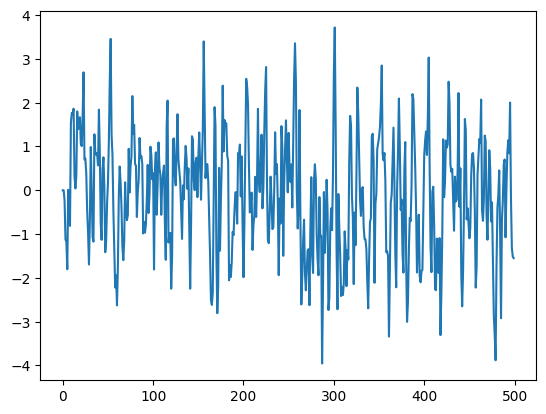

In [4]:
import numpy as np

n = 500
x = [0]*500
eps = np.random.normal(0, 1, n)

for i in range(2, n):
    x[i] = 0.7*x[i-1] -0.2*x[i-2] + eps[i]

plt.plot(x)
plt.show()

<h4> Zadanie2: Poniżej przedstawiono poziom ekspresji genu $p53$ po uszkodzeniu DNA w kolejnych chwilach czasowych $X_n$. Zbuduj model pozwalający przewidywać poziom ekspresji w oparciu o wartości z dwóch poprzednich chwil czasowych.

<h4 style="text-align:center;">$X_n = aX_{n-1}+bX_{n-2} + c+ \varepsilon_n$, gdzie $\varepsilon_n \sim N(0,\sigma)$</h4>

Możesz wykorzystać model regresji liniowej https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

- Narysuj na jednym wykresie wartości rzeczywiste i przewidywania.
- Podaj predykcje na cztery kolejne, przyszłe chwile czasowe.

In [9]:
p53 = [
    1.091, 1.089, 1.304, 1.486, 1.551,
    1.842, 2.169, 2.337, 2.445, 2.368,
    2.145, 1.947, 1.683, 1.472, 1.294,
    1.182, 1.106, 1.092, 1.015, 1.021,
    1.035, 1.071, 1.032, 1.111, 1.183,
    1.245, 1.391, 1.587, 1.847, 2.008,
    2.202, 2.322, 2.391, 2.287, 2.169,
    1.952, 1.735, 1.531, 1.348, 1.216,
    1.127, 1.086, 1.052, 1.039, 1.014,
    1.027, 1.048, 1.086, 1.119, 1.204,
    1.341, 1.534, 1.766, 1.976, 2.134,
    2.281, 2.356, 2.298, 2.174, 1.985,
    1.764, 1.566, 1.376, 1.237, 1.145,
    1.093, 1.052, 1.036, 1.021, 1.014,
    1.039, 1.075, 1.132, 1.214, 1.348,
    1.523, 1.741, 1.923, 2.105, 2.224,
    2.279, 2.234, 2.126, 1.941, 1.759,
    1.568, 1.389, 1.251, 1.152, 1.097,
    1.068, 1.039, 1.021, 1.018, 1.032,
    1.065, 1.112, 1.183, 1.274, 1.391
]

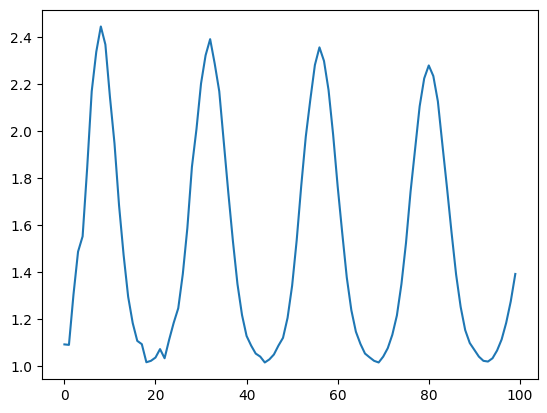

In [38]:
plt.plot(p53)
plt.show()

Komentarz do wykresu: Oscylacyjny charakter białka p53 wynika z ujemnego sprzężenia zwrotnego między p53 a białkiem MDM2:
1. Uszkodzenie DNA aktywuje p53, powodując wzrost jego poziomu.
2. p53 aktywuje ekspresję genu MDM2.
3. Białko MDM2 wiąże p53 i kieruje je do degradacji.
4. Poziom p53 spada, a wraz z nim zmniejsza się ilość MDM2.
5. p53 ponownie może się gromadzić.

In [7]:
#Jak zbudowac model regresji liniowej? Y=a1X1+a2X2+b
from sklearn.linear_model import LinearRegression
X = np.array([[1, 1], [1, 2], [2, 2], [2, 3]])
y = np.array([6, 8, 9, 11])
reg = LinearRegression().fit(X, y)
print(reg.coef_, reg.intercept_)

[1. 2.] 3.0000000000000018


<h3> Procesy gałązkowe (Galton-Watson)


Inspiracja: Czy nazwiska rodowe muszą zaniknąć, jeśli każdy mężczyzna ma losową liczbę synów?

Niech zmienne losowe $Z_0, Z_1, \dots, Z_n$ opisują liczbę osobników w kolejnych generacjach.  
Zwykle przyjmuje się $Z_0 = 1$.

$$
Z_{n+1} = \sum_{i=1}^{Z_n} X_i^{(n)}
$$

gdzie $X_i^{(n)}$ to liczba (męskich) potomków $i$-tego osobnika w generacji $n$.  
Zmienne te mają ustalony rozkład $X \sim P$.

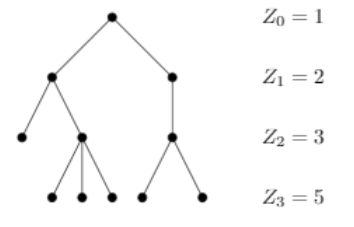

In [39]:
from IPython import display
display.Image("gw.png")

Rozważamy prawdopodobieństwo wymarcia:

$$
P_w = \lim_{n \to \infty} P(Z_n = 0)
$$

**Twierdzenie:**

$$
P_w =
\begin{cases} 
1 & \text{gdy } \mathbb{E}[X] \le 1, \\[2mm]
<1 & \text{gdy } \mathbb{E}[X] > 1.
\end{cases}
$$


<h4> Zadanie3: Załóżmy, że liczba potomków męskich ma rozkład Poissona z parametrem $\lambda = 2$.
Zasymuluj 200 losowych procesów Galtona-Watsona po 20 pokoleń, zaczynając od jednego osobnika ($Z_0=1$).
Oszacuj prawdopodobieństwo wymarcia jako odsetek symulacji, w których populacja osiągnęła 0 potomków w dowolnym momencie. Potestuj też inne parametry $\lambda$, np. 0.9, 3.

In [12]:
#Jak generować liczby z rozkładu Poissona?
np.random.poisson(5, 7) #7 obserwacji z rozkładu Poissona z Lambda = 5

array([9, 6, 6, 4, 5, 3, 6], dtype=int32)

***Twierdzenie: Dla rozkładu Poissona zachodzi: $P_w = e^{\lambda (P_w - 1)}$*** (tak można wyliczyć $P_w$, jako rozwiązanie równania)

Zastosowania:
- Biologia: dziedziczenie chromosomu Y, mitochondriów → tylko garstka mężczyzn pozostawia trwałą linię męską, większość współczesnych ludzi dziedziczy mitochondria od relatywnie niewielkiej grupy kobiet, tzw. „mitochondrialnej Ewy”.
- Epidemiologia (rozprzestrzenianie się chorób)
- Fizyka jądrowa (reakcje łańcuchowe)
- Informatyka (algorytmy wyszukiwania drzewiastego np. BFS)
- Finanse (łańcuchy aktywności rynkowej, transakcje)
